# 02 — DQN with observation noise during training

## 1. Setup

In [ ]:
from pathlib import Path

import gymnasium
import highway_env
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gymnasium import Wrapper
from stable_baselines3 import DQN
from stable_baselines3.common.callbacks import BaseCallback, EvalCallback

ENV_ID = "highway-fast-v0"
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
MODEL_PATH = str(ARTIFACTS / "model")
BEST_MODEL_PATH = str(ARTIFACTS / "best_model")
TENSORBOARD_LOG = str(ARTIFACTS / "tensorboard")
SEED = 0
TOTAL_TIMESTEPS = 20_000

SIGMA_LOW = 0.0
SIGMA_HIGH = 0.01

## 2. Environment wrapper

In [ ]:
class GaussianObsNoiseEpisodeWise(Wrapper):
    def __init__(self, env, sigma_range=(0.0, 0.01), seed=None):
        super().__init__(env)
        self.sigma_range = sigma_range
        self.rng = np.random.RandomState(seed)
        self.sigma = 0.0

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.sigma = self.rng.uniform(self.sigma_range[0], self.sigma_range[1])
        if self.sigma > 0:
            obs = obs + self.rng.randn(*obs.shape) * self.sigma
        return obs.astype(np.float32), info

    def step(self, action):
        obs, reward, done, truncated, info = self.env.step(action)
        if self.sigma > 0:
            obs = obs + self.rng.randn(*obs.shape) * self.sigma
        return obs.astype(np.float32), reward, done, truncated, info

## 2b. Callbacks

In [ ]:
class EpisodeStats(BaseCallback):
    def __init__(self):
        super().__init__()
        self.timesteps = []
        self.returns = []
        self.lengths = []
        self.crashes = []

    def _on_step(self) -> bool:
        for info in self.locals["infos"]:
            if "episode" in info:
                self.timesteps.append(self.num_timesteps)
                self.returns.append(info["episode"]["r"])
                self.lengths.append(info["episode"]["l"])
                self.crashes.append(bool(info.get("crashed", False)))
        return True

## 3. Train

In [4]:
env = GaussianObsNoiseEpisodeWise(gymnasium.make(ENV_ID), sigma_range=(SIGMA_LOW, SIGMA_HIGH), seed=SEED)
eval_env = gymnasium.make(ENV_ID)

model = DQN(
    "MlpPolicy",
    env,
    policy_kwargs=dict(net_arch=[256, 256]),
    learning_rate=5e-4,
    buffer_size=15_000,
    learning_starts=200,
    batch_size=32,
    gamma=0.8,
    train_freq=1,
    gradient_steps=1,
    target_update_interval=50,
    verbose=0,
    tensorboard_log=TENSORBOARD_LOG,
    seed=SEED,
)

stats = EpisodeStats()
eval_callback = EvalCallback(
    eval_env,
    best_model_save_path=str(ARTIFACTS),
    log_path=str(ARTIFACTS),
    eval_freq=1000,
    n_eval_episodes=10,
    deterministic=True,
    verbose=0,
)

model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=[stats, eval_callback])
model.save(MODEL_PATH)
print(f"Trained for {TOTAL_TIMESTEPS:,} steps")

/Users/frederikbach/models/.venv/lib/python3.14/site-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


/Users/frederikbach/models/.venv/lib/python3.14/site-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


/Users/frederikbach/models/.venv/lib/python3.14/site-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


/Users/frederikbach/models/.venv/lib/python3.14/site-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


/Users/frederikbach/models/.venv/lib/python3.14/site-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


/Users/frederikbach/models/.venv/lib/python3.14/site-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


... (11 outputs left out)

/Users/frederikbach/models/.venv/lib/python3.14/site-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


/Users/frederikbach/models/.venv/lib/python3.14/site-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


/Users/frederikbach/models/.venv/lib/python3.14/site-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


Trained for 20,000 steps


## Training curves (during noise training)

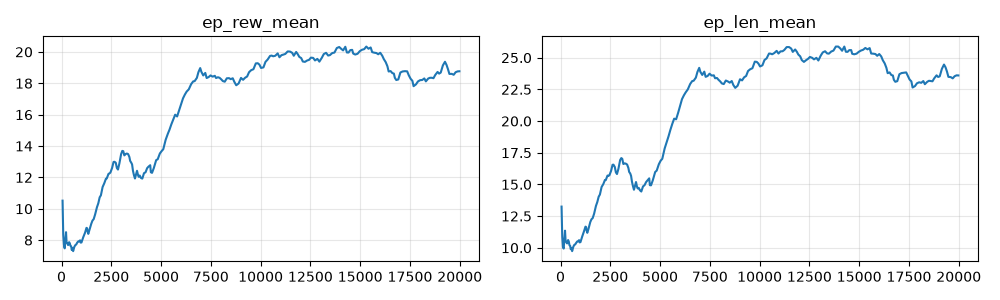

In [ ]:
# TensorBoard-style training curves (from rollout logs)
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
import glob, os

logdir = "artifacts/tensorboard"
events = glob.glob(os.path.join(logdir, '**/events.out.tfevents.*'), recursive=True)
ea = EventAccumulator(events[0])
ea.Reload()
rets = ea.Scalars('rollout/ep_rew_mean')
lens = ea.Scalars('rollout/ep_len_mean')
crash = ea.Scalars('rollout/ep_len_mean')  # not directly available; use eval

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot([r.step for r in rets], [r.value for r in rets])
axes[0].set_title('rollout/ep_rew_mean'); axes[0].set_xlabel('Timesteps'); axes[0].grid(alpha=0.3)
axes[1].plot([l.step for l in lens], [l.value for l in lens])
axes[1].set_title('rollout/ep_len_mean'); axes[1].set_xlabel('Timesteps'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
